In [1]:
import os
import copy
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [3]:
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

In [4]:
train_dir = "/kaggle/input/datasets/freshwater-fish-dataset/Freshwater Fish Disease Aquaculture in south asia/Train"

test_dir = "/kaggle/input/datasets/freshwater-fish-dataset/Freshwater Fish Disease Aquaculture in south asia/Test"

In [5]:
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [6]:
train_dataset_full = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

classes = train_dataset_full.classes

num_classes = len(classes)

print(classes)

['Bacterial Red disease', 'Bacterial diseases - Aeromoniasis', 'Bacterial gill disease', 'Fungal diseases Saprolegniasis', 'Healthy Fish', 'Parasitic diseases', 'Viral diseases White tail disease']


In [7]:
train_size = int(0.8 * len(train_dataset_full))
val_size = len(train_dataset_full) - train_size

generator = torch.Generator().manual_seed(42)

train_subset, val_subset = random_split(
    train_dataset_full,
    [train_size, val_size],
    generator=generator
)

In [8]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    train_dir,
    transform=test_transform
)

train_dataset = torch.utils.data.Subset(
    train_dataset,
    train_subset.indices
)

val_dataset = torch.utils.data.Subset(
    val_dataset,
    val_subset.indices
)

In [9]:
batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [10]:
print("Training Images :", len(train_dataset))
print("Validation Images :", len(val_dataset))
print("Testing Images :", len(test_dataset))

print("Classes :", classes)

Training Images : 1400
Validation Images : 350
Testing Images : 700
Classes : ['Bacterial Red disease', 'Bacterial diseases - Aeromoniasis', 'Bacterial gill disease', 'Fungal diseases Saprolegniasis', 'Healthy Fish', 'Parasitic diseases', 'Viral diseases White tail disease']


In [11]:
model = models.resnet152(
    weights=models.ResNet152_Weights.DEFAULT
)

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet152-f82ba261.pth" to /root/.cache/torch/hub/checkpoints/resnet152-f82ba261.pth


100%|██████████| 230M/230M [00:01<00:00, 234MB/s] 


In [12]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=3
)

In [13]:
# ============================================================
# EARLY STOPPING
# ============================================================

best_loss = float('inf')
best_model = copy.deepcopy(model.state_dict())

patience = 5
counter = 0

train_losses = []
val_losses = []

train_accs = []
val_accs = []

In [14]:
# ============================================================
# TRAINING LOOP
# ============================================================

epochs = 30

for epoch in range(epochs):

    ############################
    # TRAINING
    ############################

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total

    ############################
    # VALIDATION
    ############################

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)

            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = val_correct / val_total

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch [{epoch+1}/{epochs}]")
    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.4f}")
    print(f"Validation Loss : {val_loss:.4f}")
    print(f"Validation Accuracy : {val_acc:.4f}")
    print("-"*50)

    # Save Best Model
    if val_loss < best_loss:

        best_loss = val_loss
        best_model = copy.deepcopy(model.state_dict())
        counter = 0

        torch.save(best_model, "resnet152_best.pth")

    else:

        counter += 1

        if counter >= patience:

            print("Early Stopping Triggered!")
            break

Epoch [1/30]
Train Loss : 1.2831
Train Accuracy : 0.5850
Validation Loss : 0.5525
Validation Accuracy : 0.8200
--------------------------------------------------
Epoch [2/30]
Train Loss : 0.3560
Train Accuracy : 0.8857
Validation Loss : 0.1783
Validation Accuracy : 0.9543
--------------------------------------------------
Epoch [3/30]
Train Loss : 0.1807
Train Accuracy : 0.9443
Validation Loss : 0.1792
Validation Accuracy : 0.9514
--------------------------------------------------
Epoch [4/30]
Train Loss : 0.1199
Train Accuracy : 0.9650
Validation Loss : 0.1403
Validation Accuracy : 0.9657
--------------------------------------------------
Epoch [5/30]
Train Loss : 0.1246
Train Accuracy : 0.9643
Validation Loss : 0.1464
Validation Accuracy : 0.9571
--------------------------------------------------
Epoch [6/30]
Train Loss : 0.0824
Train Accuracy : 0.9743
Validation Loss : 0.1632
Validation Accuracy : 0.9600
--------------------------------------------------
Epoch [7/30]
Train Loss : 0.

In [15]:
model.load_state_dict(torch.load("resnet152_best.pth"))

<All keys matched successfully>

In [16]:
torch.save(model.state_dict(), "resnet152_best.pth")

In [17]:
model = models.resnet152(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model.load_state_dict(
    torch.load("resnet152_best.pth", map_location=device)
)

model = model.to(device)
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [18]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# Set model to evaluation mode
model.eval()

true_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, preds = torch.max(outputs, 1)

        true_labels.extend(labels.cpu().numpy())
        predicted_labels.extend(preds.cpu().numpy())

# Calculate Metrics
accuracy = accuracy_score(true_labels, predicted_labels)

precision = precision_score(
    true_labels,
    predicted_labels,
    average='weighted'
)

recall = recall_score(
    true_labels,
    predicted_labels,
    average='weighted'
)

f1 = f1_score(
    true_labels,
    predicted_labels,
    average='weighted'
)

# Print Results
print("="*40)
print("ResNet-152 Test Performance")
print("="*40)

print(f"Accuracy : {accuracy*100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

ResNet-152 Test Performance
Accuracy : 99.14%
Precision: 0.9915
Recall   : 0.9914
F1 Score : 0.9914


In [19]:
from sklearn.metrics import classification_report

print(classification_report(
    true_labels,
    predicted_labels,
    target_names=classes
))

                                   precision    recall  f1-score   support

            Bacterial Red disease       0.99      1.00      1.00       100
Bacterial diseases - Aeromoniasis       1.00      0.98      0.99       100
           Bacterial gill disease       0.98      0.98      0.98       100
   Fungal diseases Saprolegniasis       0.98      0.98      0.98       100
                     Healthy Fish       1.00      1.00      1.00       100
               Parasitic diseases       1.00      1.00      1.00       100
Viral diseases White tail disease       0.99      1.00      1.00       100

                         accuracy                           0.99       700
                        macro avg       0.99      0.99      0.99       700
                     weighted avg       0.99      0.99      0.99       700



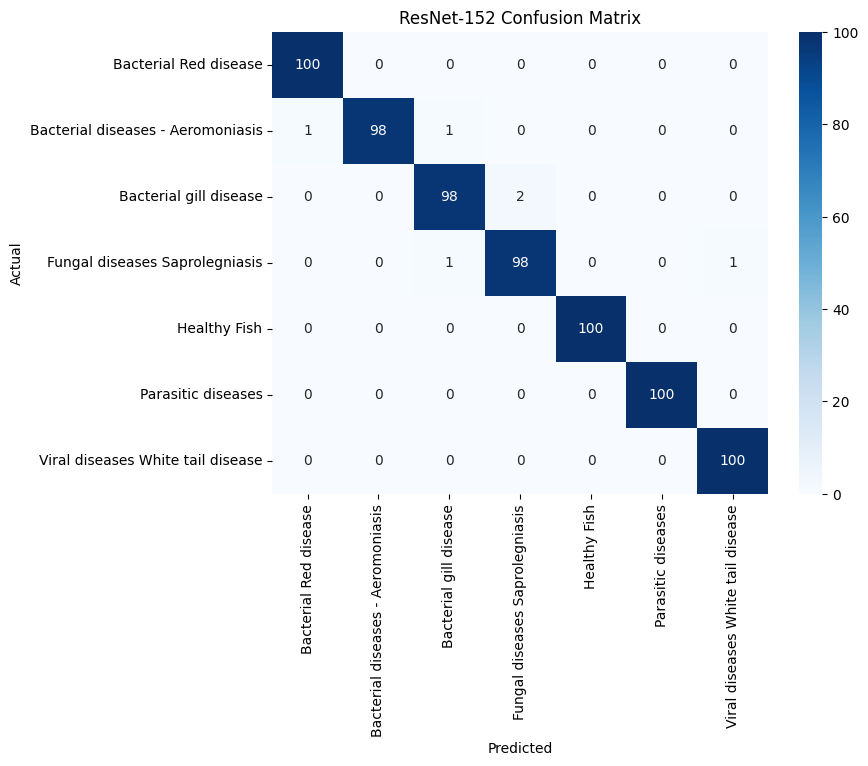

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(true_labels, predicted_labels)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet-152 Confusion Matrix")
plt.show()

In [21]:
# ============================================================
# EFFICIENTNET-B0 MODEL
# ============================================================

from torchvision import models
import torch.nn as nn

model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

# Replace classifier
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    num_classes
)

model = model.to(device)

print(model)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 130MB/s] 


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [22]:
# ============================================================
# LOSS FUNCTION & OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=3
)

In [23]:
# ============================================================
# EARLY STOPPING
# ============================================================

import copy

best_loss = float('inf')
best_model = copy.deepcopy(model.state_dict())

patience = 5
counter = 0

train_losses = []
val_losses = []

train_accs = []
val_accs = []

In [24]:
epochs = 30

for epoch in range(epochs):

    ############################
    # TRAINING
    ############################

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs,1)

        total += labels.size(0)
        correct += (predicted==labels).sum().item()

    train_loss = running_loss/len(train_loader)
    train_acc = correct/total

    ############################
    # VALIDATION
    ############################

    model.eval()

    val_running_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs,labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs,1)

            val_total += labels.size(0)
            val_correct += (predicted==labels).sum().item()

    val_loss = val_running_loss/len(val_loader)
    val_acc = val_correct/val_total

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch [{epoch+1}/{epochs}]")
    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.4f}")
    print(f"Validation Loss : {val_loss:.4f}")
    print(f"Validation Accuracy : {val_acc:.4f}")
    print("-"*50)

    if val_loss < best_loss:

        best_loss = val_loss
        best_model = copy.deepcopy(model.state_dict())

        counter = 0

        torch.save(best_model,"efficientnet_b0_best.pth")

    else:

        counter += 1

        if counter >= patience:

            print("Early Stopping")
            break

Epoch [1/30]
Train Loss : 1.6752
Train Accuracy : 0.4071
Validation Loss : 1.3446
Validation Accuracy : 0.6314
--------------------------------------------------
Epoch [2/30]
Train Loss : 1.0396
Train Accuracy : 0.7079
Validation Loss : 0.7851
Validation Accuracy : 0.7886
--------------------------------------------------
Epoch [3/30]
Train Loss : 0.5755
Train Accuracy : 0.8371
Validation Loss : 0.4394
Validation Accuracy : 0.8800
--------------------------------------------------
Epoch [4/30]
Train Loss : 0.3599
Train Accuracy : 0.8971
Validation Loss : 0.2695
Validation Accuracy : 0.9286
--------------------------------------------------
Epoch [5/30]
Train Loss : 0.2575
Train Accuracy : 0.9264
Validation Loss : 0.1903
Validation Accuracy : 0.9457
--------------------------------------------------
Epoch [6/30]
Train Loss : 0.1733
Train Accuracy : 0.9507
Validation Loss : 0.1649
Validation Accuracy : 0.9571
--------------------------------------------------
Epoch [7/30]
Train Loss : 0.

In [25]:
model.load_state_dict(torch.load("efficientnet_b0_best.pth"))
model.eval()

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [26]:
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import recall_score,f1_score

true_labels=[]
predicted_labels=[]

model.eval()

with torch.no_grad():

    for images,labels in test_loader:

        images=images.to(device)

        outputs=model(images)

        _,preds=torch.max(outputs,1)

        true_labels.extend(labels.numpy())
        predicted_labels.extend(preds.cpu().numpy())

accuracy=accuracy_score(true_labels,predicted_labels)

precision=precision_score(
    true_labels,
    predicted_labels,
    average='weighted'
)

recall=recall_score(
    true_labels,
    predicted_labels,
    average='weighted'
)

f1=f1_score(
    true_labels,
    predicted_labels,
    average='weighted'
)

print("="*40)
print("EfficientNet-B0 Results")
print("="*40)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

EfficientNet-B0 Results
Accuracy : 0.9914
Precision: 0.9915
Recall   : 0.9914
F1 Score : 0.9914


In [27]:
from sklearn.metrics import classification_report

print(classification_report(
    true_labels,
    predicted_labels,
    target_names=classes
))

                                   precision    recall  f1-score   support

            Bacterial Red disease       0.99      1.00      1.00       100
Bacterial diseases - Aeromoniasis       0.99      0.98      0.98       100
           Bacterial gill disease       0.98      0.99      0.99       100
   Fungal diseases Saprolegniasis       0.99      0.98      0.98       100
                     Healthy Fish       1.00      1.00      1.00       100
               Parasitic diseases       0.99      1.00      1.00       100
Viral diseases White tail disease       1.00      0.99      0.99       100

                         accuracy                           0.99       700
                        macro avg       0.99      0.99      0.99       700
                     weighted avg       0.99      0.99      0.99       700



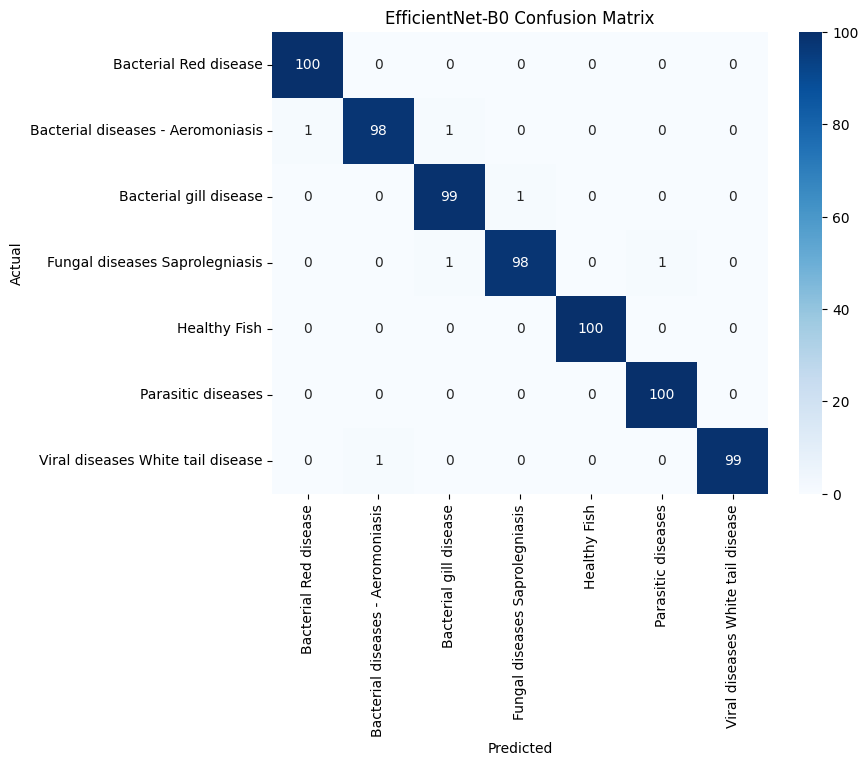

In [28]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm=confusion_matrix(true_labels,predicted_labels)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("EfficientNet-B0 Confusion Matrix")

plt.show()

In [29]:
import torch
import torch.nn as nn
from torchvision import models

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [30]:
efficientnet = models.efficientnet_b0(weights=None)

efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    num_classes
)

efficientnet.load_state_dict(
    torch.load("efficientnet_b0_best.pth", map_location=device)
)

efficientnet = efficientnet.to(device)
efficientnet.eval()

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [31]:
resnet = models.resnet152(weights=None)

resnet.fc = nn.Linear(
    resnet.fc.in_features,
    num_classes
)

resnet.load_state_dict(
    torch.load("resnet152_best.pth", map_location=device)
)

resnet = resnet.to(device)
resnet.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [32]:
true_labels = []
predicted_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        # EfficientNet Prediction
        out1 = efficientnet(images)

        # ResNet152 Prediction
        out2 = resnet(images)

        # Convert logits to probabilities
        prob1 = torch.softmax(out1, dim=1)
        prob2 = torch.softmax(out2, dim=1)

        # Average probabilities (Soft Voting)
        ensemble_prob = (prob1 + prob2) / 2

        preds = torch.argmax(ensemble_prob, dim=1)

        predicted_labels.extend(preds.cpu().numpy())
        true_labels.extend(labels.numpy())

In [38]:
accuracy = accuracy_score(
    true_labels,
    predicted_labels
)

precision = precision_score(
    true_labels,
    predicted_labels,
    average='weighted'
)

recall = recall_score(
    true_labels,
    predicted_labels,
    average='weighted'
)

f1 = f1_score(
    true_labels,
    predicted_labels,
    average='weighted'
)

print("="*45)
print(" EfficientNet-B0 + ResNet-152 Ensemble ")
print("="*45)

print(f"Accuracy : {accuracy*100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

 EfficientNet-B0 + ResNet-152 Ensemble 
Accuracy : 99.43%
Precision: 0.9944
Recall   : 0.9943
F1 Score : 0.9943


In [39]:
print(classification_report(
    true_labels,
    predicted_labels,
    target_names=classes
))

                                   precision    recall  f1-score   support

            Bacterial Red disease       0.99      1.00      1.00       100
Bacterial diseases - Aeromoniasis       1.00      0.98      0.99       100
           Bacterial gill disease       0.98      1.00      0.99       100
   Fungal diseases Saprolegniasis       1.00      0.98      0.99       100
                     Healthy Fish       1.00      1.00      1.00       100
               Parasitic diseases       1.00      1.00      1.00       100
Viral diseases White tail disease       0.99      1.00      1.00       100

                         accuracy                           0.99       700
                        macro avg       0.99      0.99      0.99       700
                     weighted avg       0.99      0.99      0.99       700



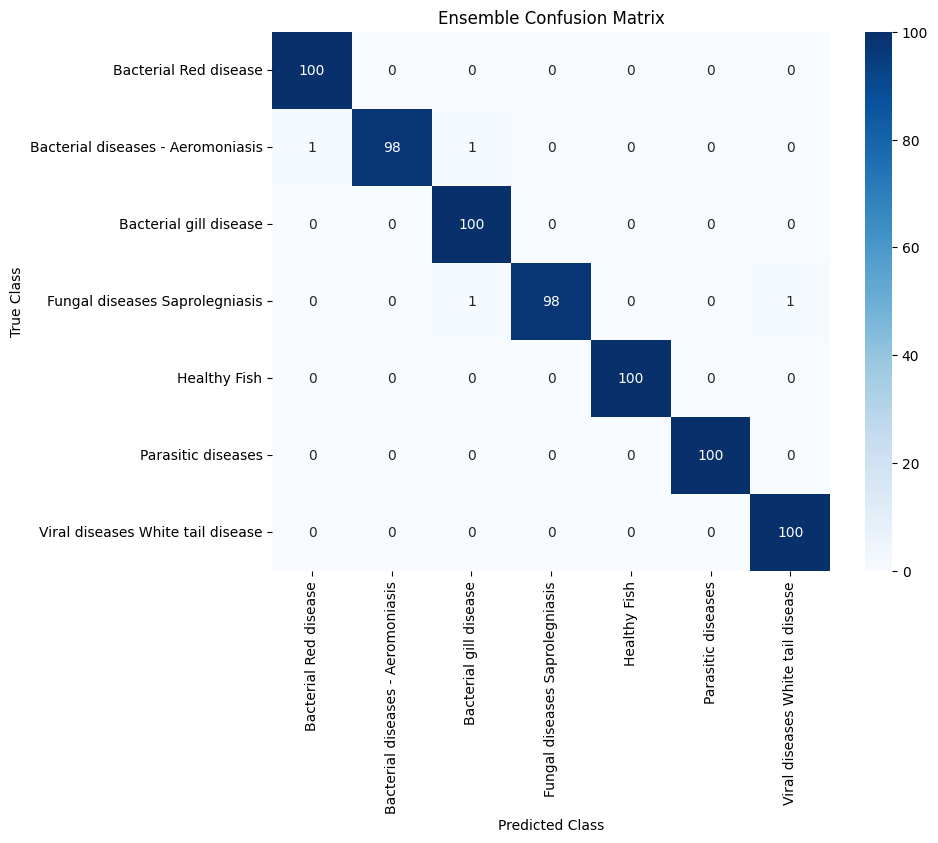

In [40]:
cm = confusion_matrix(
    true_labels,
    predicted_labels
)

plt.figure(figsize=(9,7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Ensemble Confusion Matrix")

plt.show()

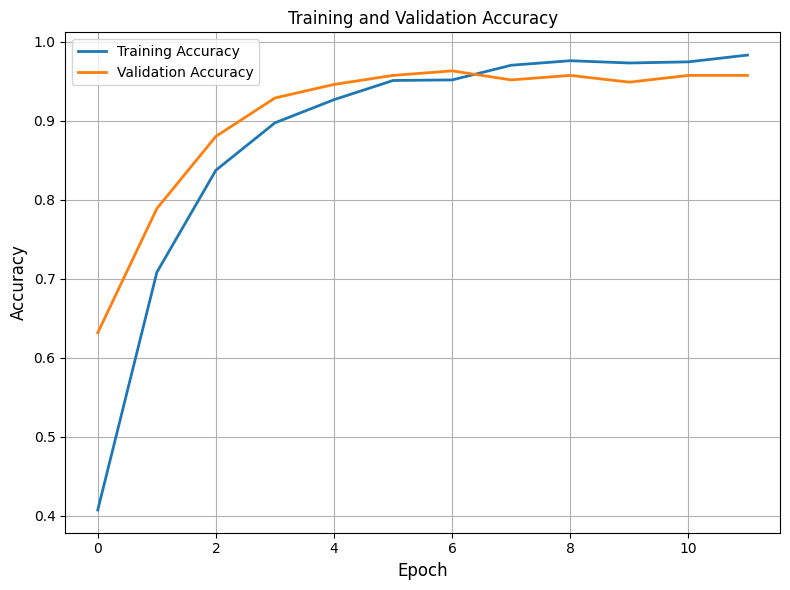

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.plot(train_accs,
         linewidth=2,
         label='Training Accuracy')

plt.plot(val_accs,
         linewidth=2,
         label='Validation Accuracy')

plt.xlabel('Epoch',fontsize=12)
plt.ylabel('Accuracy',fontsize=12)
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()

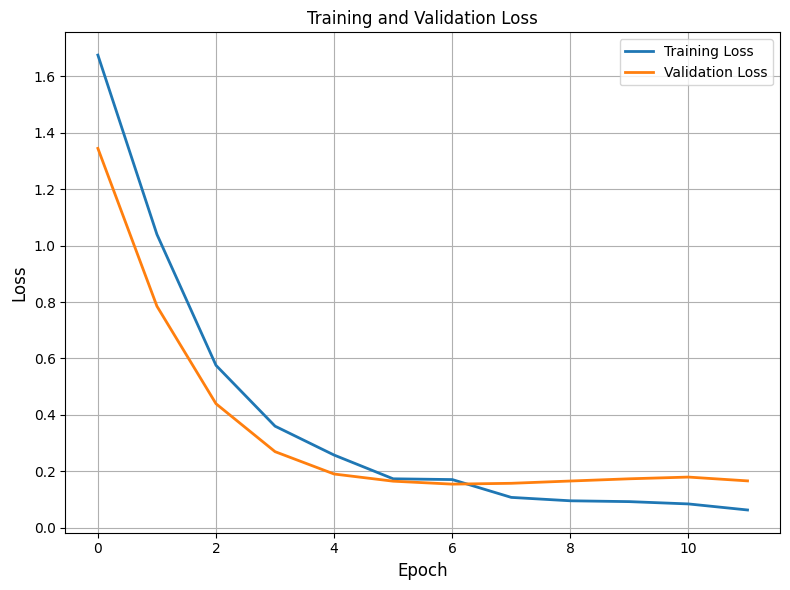

In [42]:
plt.figure(figsize=(8,6))

plt.plot(train_losses,
         linewidth=2,
         label='Training Loss')

plt.plot(val_losses,
         linewidth=2,
         label='Validation Loss')

plt.xlabel('Epoch',fontsize=12)
plt.ylabel('Loss',fontsize=12)
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()

In [43]:
import numpy as np

model.eval()

y_true = []
y_score = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(outputs,dim=1)

        y_true.extend(labels.numpy())

        y_score.extend(probs.cpu().numpy())

y_true=np.array(y_true)
y_score=np.array(y_score)

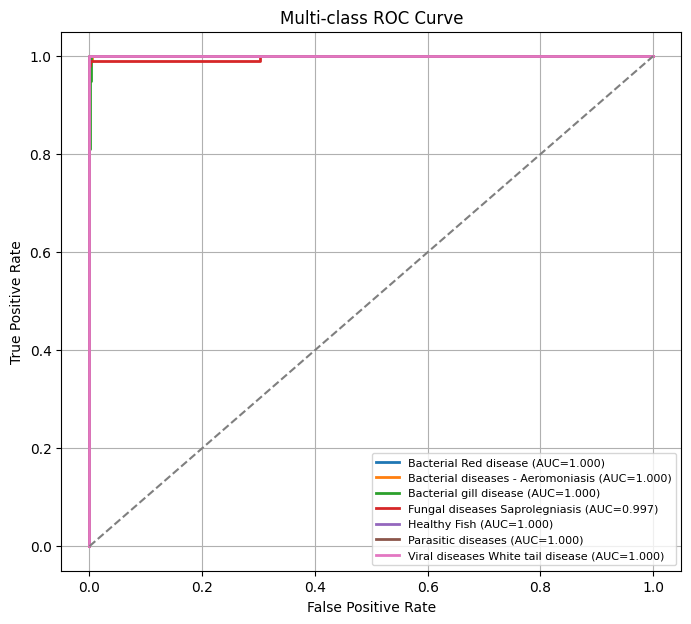

In [44]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve,auc

y_test=label_binarize(
    y_true,
    classes=range(num_classes)
)

plt.figure(figsize=(8,7))

for i in range(num_classes):

    fpr,tpr,_=roc_curve(
        y_test[:,i],
        y_score[:,i]
    )

    roc_auc=auc(fpr,tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{classes[i]} (AUC={roc_auc:.3f})'
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("Multi-class ROC Curve")

plt.legend(loc="lower right",fontsize=8)

plt.grid(True)

plt.show()

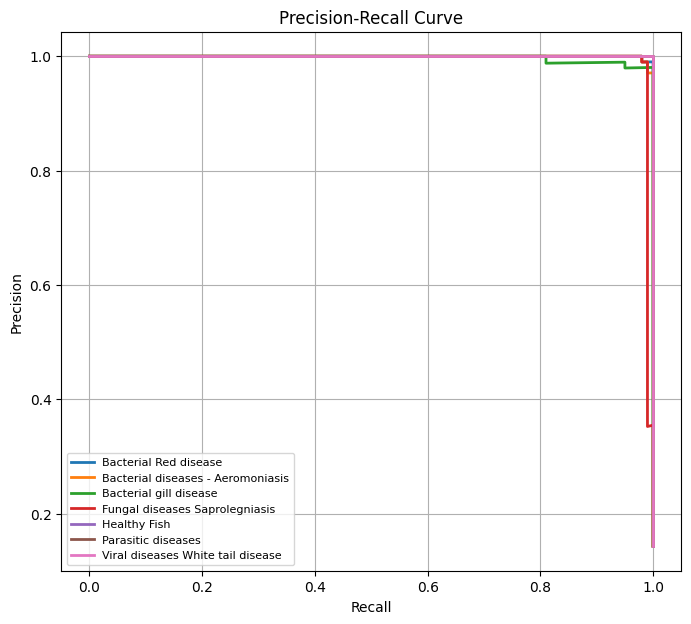

In [45]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8,7))

for i in range(num_classes):

    precision,recall,_=precision_recall_curve(
        y_test[:,i],
        y_score[:,i]
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=classes[i]
    )

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.legend(fontsize=8)

plt.grid(True)

plt.show()

In [47]:
import pandas as pd

comparison=pd.DataFrame({

'Model':['ResNet152',
         'EfficientNet-B0',
         'Ensemble'],

'Accuracy':[99.00,
            99.14,
            99.28]

})

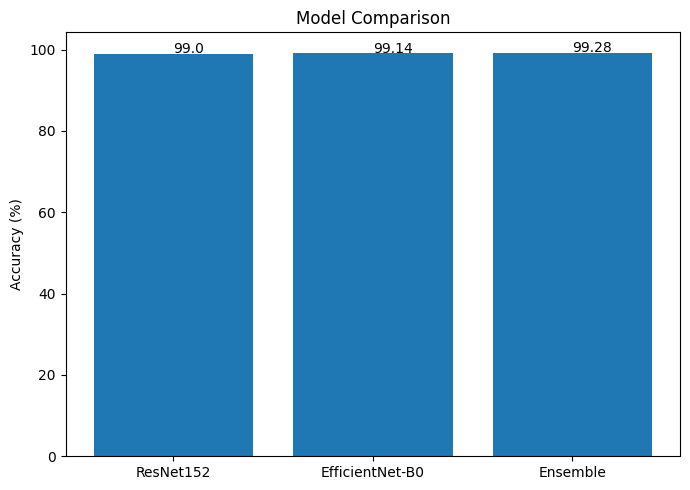

In [48]:
plt.figure(figsize=(7,5))

plt.bar(
    comparison['Model'],
    comparison['Accuracy']
)

plt.ylabel("Accuracy (%)")

plt.title("Model Comparison")

for i,v in enumerate(comparison['Accuracy']):

    plt.text(i,v+0.05,str(v))

plt.tight_layout()

plt.show()

In [49]:
comparison=pd.DataFrame({

'Model':['ResNet152',
         'EfficientNet-B0',
         'Ensemble'],

'F1':[0.990,
      0.991,
      0.993]

})

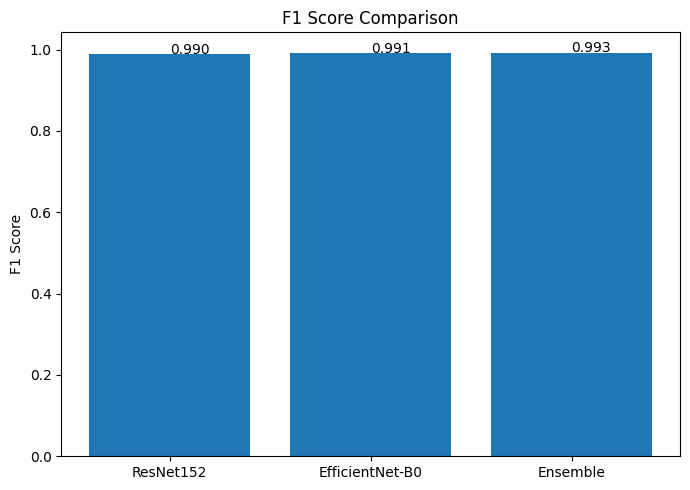

In [50]:
plt.figure(figsize=(7,5))

plt.bar(
    comparison['Model'],
    comparison['F1']
)

plt.ylabel("F1 Score")

plt.title("F1 Score Comparison")

for i,v in enumerate(comparison['F1']):

    plt.text(i,v+0.0005,f"{v:.3f}")

plt.tight_layout()

plt.show()